# Homework 3

Data preparation

Check if the missing values are presented in the features.

If there are missing values:

For categorical features, replace them with 'NA'

For numerical features, replace with with 0.0

In [1]:
import pandas as pd
import numpy as np

In [2]:
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
df = pd.read_csv(url)

In [3]:
missing_data = df.isnull().sum()
print(missing_data)

categorical_cols = df.select_dtypes(include=['object', 'category']).columns
numerical_cols = df.select_dtypes(include=[np.number]).columns

df[categorical_cols] = df[categorical_cols].fillna('NA')
df[numerical_cols] = df[numerical_cols].fillna(0.0)

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64


/tmp/ipykernel_2300/2914113723.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object', 'category']).columns


Question 1
What is the most frequent observation (mode) for the column industry?

NA

technology

healthcare

retail

In [4]:
industry_cols = df['industry'].value_counts()
print(industry_cols)

industry_mode = df['industry'].mode()[0]
print(f"The most frequent observation (mode) for the column industry is: {industry_mode}.")

industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
NA                240
Name: count, dtype: int64
The most frequent observation (mode) for the column industry is: technology.


Create the correlation matrix for the numerical features of your dataset. In a correlation matrix, you compute the correlation coefficient between every pair of features.

What are the two features that have the biggest correlation?

interaction_count and lead_score

number_of_courses_viewed and lead_score

number_of_courses_viewed and interaction_count

annual_income and interaction_count


Only consider the pairs above when answering this question.



In [5]:
numerical_cols = [
    'interaction_count',
    'lead_score',
    'number_of_courses_viewed',
    'annual_income',
]
df[numerical_cols].corr()

,interaction_count,lead_score,number_of_courses_viewed,annual_income
interaction_count,1.000000,0.915746,0.721609,0.122842
lead_score,0.915746,1.000000,0.757204,0.229496
number_of_courses_viewed,0.721609,0.757204,1.000000,0.161300
annual_income,0.122842,0.229496,0.161300,1.000000


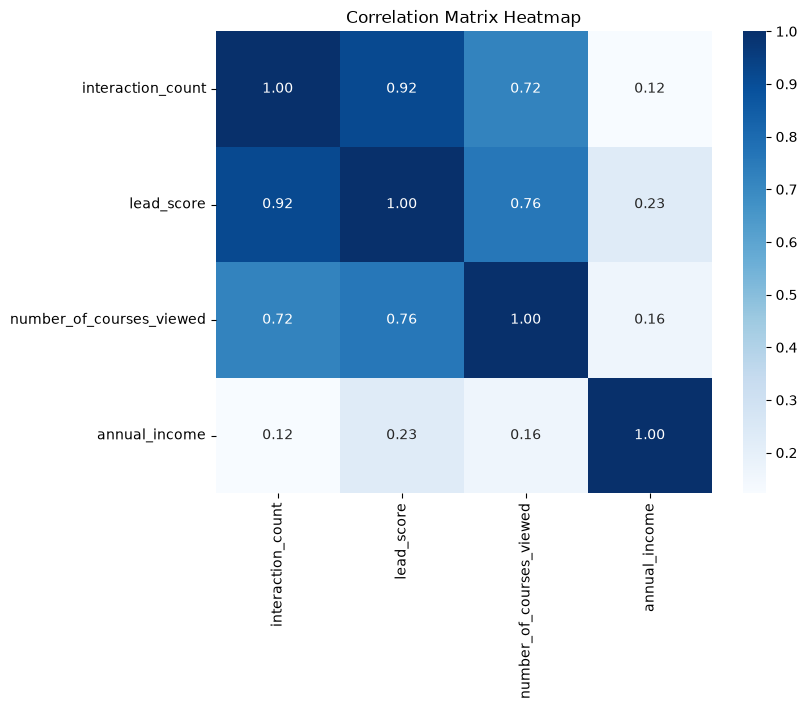

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(df[numerical_cols].corr(), annot=True, cmap="Blues", fmt=".2f")
plt.title("Correlation Matrix Heatmap")
plt.show()

In [7]:
corr_matrix = df[numerical_cols].corr()

unstacked_corr = (
    corr_matrix.abs()
    .where(~(corr_matrix == 1.0))
    .unstack()
    .dropna()
    .sort_values(ascending=False)
)

pair, val = unstacked_corr.index[0], unstacked_corr.iloc[0]
print(
    f"Strongest correlation: {pair[0]} & {pair[1]} with r = {corr_matrix.loc[pair[0], pair[1]]:.4f}"
)

Strongest correlation: interaction_count & lead_score with r = 0.9157


Split the data

Split the data with these exact calls:

df_full_train, df_test = train_test_split(df, 

test_size=0.2, random_state=42)

df_train, df_val = train_test_split(

    df_full_train, test_size=0.25, random_state=42
)


Make sure that the target value converted is not in your dataframe.

In [8]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


Question 3
Calculate the mutual information score between converted and other categorical variables in the dataset. Use the training set only.
Round the scores to 2 decimals using round(score, 2).
Which of these variables has the biggest mutual information score?

industry

location

lead_source

employment_status

In [9]:
from sklearn.metrics import mutual_info_score
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train["converted"]

categorical = ["industry", "location", "lead_source", "employment_status"]

def calculate_mi(series):
    # Handle missing values if any by filling with a placeholder string
    series = series.fillna("missing")
    return mutual_info_score(series, y_train)


mi_scores = df_train[categorical].apply(calculate_mi)
mi_scores = mi_scores.round(2).sort_values(ascending=False)

print("Mutual Information Scores:")
print(mi_scores)

Mutual Information Scores:
lead_source          0.03
employment_status    0.02
location             0.00
industry             0.00
dtype: float64


Question 4
Now let's train a logistic regression.
Remember that we have several categorical variables in the dataset. Include them using one-hot encoding.

Fit the model on the training dataset.
To make sure the results are reproducible across different versions of Scikit-Learn, fit the model with these parameters:

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
Calculate the accuracy on the validation dataset and round it to 2 decimal digits.
What accuracy did you get?

0.55

0.65

0.75

0.85


In [10]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Train data dictionaries
train_dicts = df_train.drop(columns=["converted"]).to_dict(orient="records")
val_dicts = df_val.drop(columns=["converted"]).to_dict(orient="records")

# One-Hot Encoding using DictVectorizer
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

# Retrieve target variables
y_train = df_train["converted"].values
y_val = df_val["converted"].values

# Commence logistic Regression model with exact parameters
model = LogisticRegression(
    solver="liblinear", C=1.0, max_iter=1000, random_state=42
)
model.fit(X_train, y_train)

# Calculate accuracy on the validation dataset
y_pred = model.predict(X_val)
accuracy = accuracy_score(y_val, y_pred)

print(f"Validation Accuracy: {round(accuracy, 2)}")

Validation Accuracy: 0.65


Question 5
Let's find the least useful feature using the feature elimination technique.

Train a model using the same features and parameters as in Q4 (without rounding).
Now exclude each feature from this set and train a model without it. Record the accuracy for each model.

For each feature, calculate the difference between the original accuracy and the accuracy without the feature.

Which of following feature has the smallest difference?

'lead_source'

'number_of_courses_viewed''

'interaction_count'

Note: The difference doesn't have to be positive.

In [11]:
# Baseline accuracy with all features
base_acc = accuracy

differences = {}

# List of features to test dropping
features_to_test = ["lead_source", "number_of_courses_viewed", "interaction_count"]

for drop_feature in features_to_test:
    # Create modified train/val dicts without the dropped feature
    train_dicts_subset = (
        df_train.drop(columns=["converted", drop_feature])
        .to_dict(orient="records")
    )
    val_dicts_subset = (
        df_val.drop(columns=["converted", drop_feature]).to_dict(orient="records")
    )

    # Vectorize
    dv_sub = DictVectorizer(sparse=False)
    X_train_sub = dv_sub.fit_transform(train_dicts_subset)
    X_val_sub = dv_sub.transform(val_dicts_subset)

    # Train model
    sub_model = LogisticRegression(
        solver="liblinear", C=1.0, max_iter=1000, random_state=42
    )
    sub_model.fit(X_train_sub, y_train)

    # Evaluate
    sub_acc = accuracy_score(y_val, sub_model.predict(X_val_sub))

    # Difference: original accuracy - accuracy without the feature
    diff = base_acc - sub_acc
    differences[drop_feature] = diff
    print(f"Without {drop_feature}: accuracy = {sub_acc:.5f}, diff = {diff:.5f}")

# Find feature with the smallest difference
smallest_feature = min(differences, key=lambda k: abs(differences[k]))
print(
    f"\nFeature with the smallest difference: {smallest_feature} ({differences[smallest_feature]:.5f})"
)

Without lead_source: accuracy = 0.64200, diff = 0.00300
Without number_of_courses_viewed: accuracy = 0.64300, diff = 0.00200
Without interaction_count: accuracy = 0.60100, diff = 0.04400

Feature with the smallest difference: number_of_courses_viewed (0.00200)


Question 6
Now let's train a regularized logistic regression.
Let's try the following values of the parameter C: [0.000001, 0.00001, 0.0001, 0.001].
Train models using all the features as in Q4.
Calculate the accuracy on the validation dataset and round it to 3 decimal digits.
Which of these C leads to the best accuracy on the validation set?

0.000001

0.00001

0.0001

0.001

Note: If there are multiple options, select the smallest C.



In [12]:
# List of C values to test
c_values = [0.000001, 0.00001, 0.0001, 0.001]

best_c = None
best_acc = 0.0

for c in c_values:
    # Initialize and train model with current C value
    model_c = LogisticRegression(
        solver="liblinear", C=c, max_iter=1000, random_state=42
    )
    model_c.fit(X_train, y_train)

    # Predict and evaluate on validation set
    y_pred_c = model_c.predict(X_val)
    acc = accuracy_score(y_val, y_pred_c)
    rounded_acc = round(acc, 3)

    print(f"C = {c} -> Validation Accuracy = {rounded_acc} (exact: {acc:.5f})")

    # Track best accuracy (with tie-handling favoring the smallest C as noted)
    if acc > best_acc:
        best_acc = acc
        best_c = c

print(f"\nBest C value: {best_c} with accuracy: {round(best_acc, 3)}")

C = 1e-06 -> Validation Accuracy = 0.598 (exact: 0.59800)
C = 1e-05 -> Validation Accuracy = 0.598 (exact: 0.59800)
C = 0.0001 -> Validation Accuracy = 0.613 (exact: 0.61300)
C = 0.001 -> Validation Accuracy = 0.645 (exact: 0.64500)

Best C value: 0.001 with accuracy: 0.645
